<a href="https://colab.research.google.com/github/the-name-is-madhu/BIS_LAB/blob/main/1BM24CS154__Smart_Electricity_Load_Scheduling__Particle_Swarm_Optimization_Problem_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running Particle Swarm Optimization Load Scheduler...

--- Results Summary ---
Baseline Daily Cost: $4.85
PSO Optimized Cost:  $4.85
Total Financial Savings: $0.00 (0.0%)
-----------------------

Optimal Appliance Start Schedules:
 - Washing Machine  : Set to turn ON at hour 08:00
 - Dishwasher       : Set to turn ON at hour 12:00
 - EV Charger       : Set to turn ON at hour 00:00
 - Water Heater     : Set to turn ON at hour 05:00


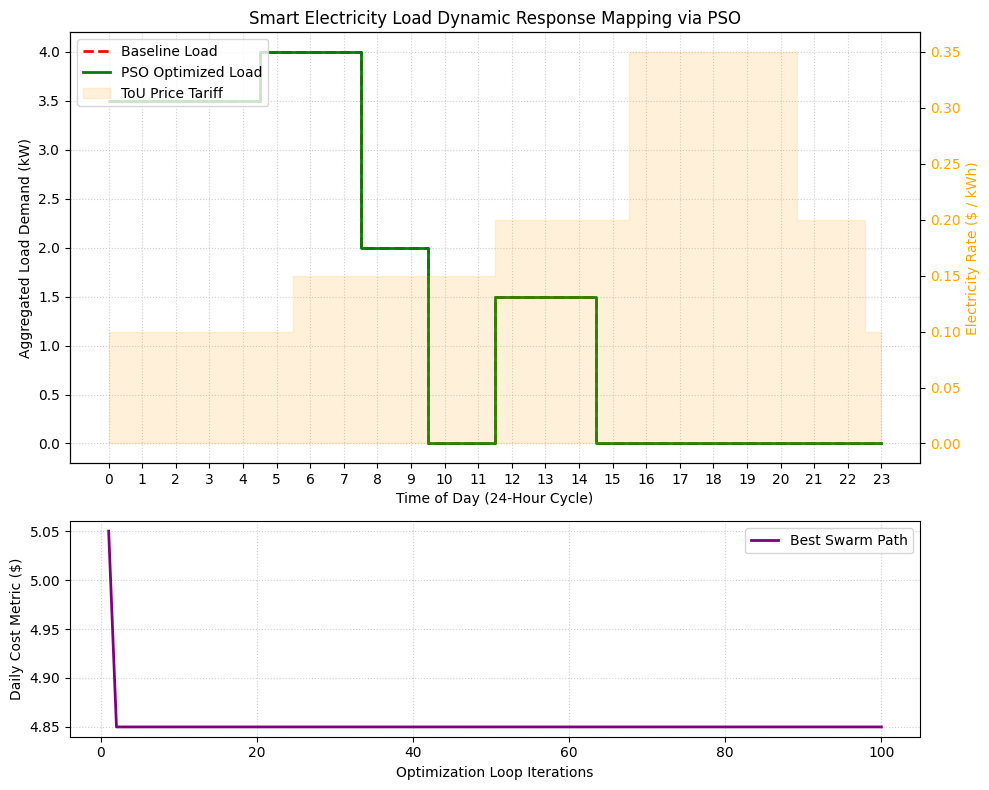

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. ENVIRONMENT CONFIGURATION
# ---------------------------------------------------------
HOURS = 24
POP_SIZE = 50       # Number of particles in the swarm
ITERATIONS = 100    # Number of optimization steps
W = 0.5            # Inertia weight
C1 = 1.5           # Cognitive (personal best) coefficient
C2 = 1.5           # Social (global best) coefficient

# Time-of-Use (ToU) Tariff Profile ($ per kWh)
# Off-Peak: $0.10, Mid-Peak: $0.15/$0.20, Peak (Hours 16-20): $0.35
TARIFF = np.array([0.10]*6 + [0.15]*6 + [0.20]*4 + [0.35]*5 + [0.20]*2 + [0.10]*1)

# Appliance Definitions: [Power (kW), Duration (Hours), Earliest Start, Latest End]
APPLIANCES = {
    'Washing Machine': {'power': 2.0, 'duration': 2, 'start_window': 8, 'end_window': 22},
    'Dishwasher':      {'power': 1.5, 'duration': 3, 'start_window': 12, 'end_window': 23},
    'EV Charger':       {'power': 3.5, 'duration': 5, 'start_window': 0, 'end_window': 24},
    'Water Heater':    {'power': 4.0, 'duration': 3, 'start_window': 5, 'end_window': 20}
}
APP_KEYS = list(APPLIANCES.keys())
NUM_APPS = len(APP_KEYS)

# ---------------------------------------------------------
# 2. HELPER FUNCTIONS: BOUNDARY REPAIR & COST EVALUATION
# ---------------------------------------------------------
def repair_position(pos):
    """
    Translates raw continuous particle positions into valid, non-breaking
    operational start times while strictly adhering to user comfort windows.
    """
    repaired_start_times = np.zeros(NUM_APPS, dtype=int)
    for idx, app in enumerate(APP_KEYS):
        config = APPLIANCES[app]

        # Max allowable start hour to prevent execution extending past the deadline
        max_possible_start = config['end_window'] - config['duration']
        min_possible_start = config['start_window']

        # Clip positions within limits, map to integers
        raw_val = int(np.round(pos[idx]))
        repaired_start_times[idx] = np.clip(raw_val, min_possible_start, max_possible_start)

    return repaired_start_times

def calculate_load_profile(start_times):
    """Calculates aggregate grid load over a 24-hour cycle based on start points."""
    load_profile = np.zeros(HOURS)
    for idx, app in enumerate(APP_KEYS):
        start = start_times[idx]
        duration = APPLIANCES[app]['duration']
        power = APPLIANCES[app]['power']
        load_profile[start : start + duration] += power
    return load_profile

def evaluate_fitness(start_times):
    """Evaluates total cost of electricity based on schedule."""
    load_profile = calculate_load_profile(start_times)
    total_cost = np.sum(load_profile * TARIFF)
    return total_cost

# ---------------------------------------------------------
# 3. CORE PARTICLE SWARM OPTIMIZATION ENGINE
# ---------------------------------------------------------
def run_pso():
    # Positions track the starting hour for each appliance
    positions = np.zeros((POP_SIZE, NUM_APPS))
    velocities = np.random.uniform(-2, 2, size=(POP_SIZE, NUM_APPS))

    # Initialize particle positions randomly within boundaries
    for p in range(POP_SIZE):
        for idx, app in enumerate(APP_KEYS):
            config = APPLIANCES[app]
            max_start = config['end_window'] - config['duration']
            positions[p, idx] = np.random.randint(config['start_window'], max_start + 1)

    pbest_positions = np.copy(positions)
    pbest_fitness = np.array([evaluate_fitness(repair_position(p)) for p in positions])

    gbest_idx = np.argmin(pbest_fitness)
    gbest_position = np.copy(pbest_positions[gbest_idx])
    gbest_fitness = pbest_fitness[gbest_idx]

    convergence_history = []

    # Optimization Loop
    for iteration in range(ITERATIONS):
        for p in range(POP_SIZE):
            # Velocity update math
            r1, r2 = np.random.rand(NUM_APPS), np.random.rand(NUM_APPS)
            velocities[p] = (W * velocities[p] +
                             C1 * r1 * (pbest_positions[p] - positions[p]) +
                             C2 * r2 * (gbest_position - positions[p]))

            # Position updates
            positions[p] += velocities[p]

            # Clean positions and evaluate new fitness values
            repaired_schedule = repair_position(positions[p])
            current_fitness = evaluate_fitness(repaired_schedule)

            # Personal best updates
            if current_fitness < pbest_fitness[p]:
                pbest_fitness[p] = current_fitness
                pbest_positions[p] = np.copy(positions[p])

        # Global best updates
        best_of_swarm_idx = np.argmin(pbest_fitness)
        if pbest_fitness[best_of_swarm_idx] < gbest_fitness:
            gbest_fitness = pbest_fitness[best_of_swarm_idx]
            gbest_position = np.copy(pbest_positions[best_of_swarm_idx])

        convergence_history.append(gbest_fitness)

    return repair_position(gbest_position), convergence_history

# ---------------------------------------------------------
# 4. EXECUTION & RESULTS VISUALIZATION
# ---------------------------------------------------------
if __name__ == "__main__":
    # 1. Baseline: Force everything to run right at the start of preferred windows
    baseline_starts = np.array([APPLIANCES[app]['start_window'] for app in APP_KEYS])
    baseline_load = calculate_load_profile(baseline_starts)
    baseline_cost = evaluate_fitness(baseline_starts)

    # 2. Run Optimization Engine
    print("Running Particle Swarm Optimization Load Scheduler...")
    optimal_starts, history = run_pso()
    optimized_load = calculate_load_profile(optimal_starts)
    optimized_cost = evaluate_fitness(optimal_starts)
    savings = baseline_cost - optimized_cost
    pct_savings = (savings / baseline_cost) * 100

    # Print metrics terminal summary
    print("\n--- Results Summary ---")
    print(f"Baseline Daily Cost: ${baseline_cost:.2f}")
    print(f"PSO Optimized Cost:  ${optimized_cost:.2f}")
    print(f"Total Financial Savings: ${savings:.2f} ({pct_savings:.1f}%)")
    print("-----------------------")
    print("\nOptimal Appliance Start Schedules:")
    for i, app in enumerate(APP_KEYS):
        print(f" - {app:16s} : Set to turn ON at hour {optimal_starts[i]:02d}:00")

    # 3. Plotting Results Environment
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={'height_ratios': [2, 1]})

    # Plot 1: Load Profile vs Tariff Pricing
    ax1.step(range(HOURS), baseline_load, where='mid', label='Baseline Load', color='red', linestyle='--', linewidth=2)
    ax1.step(range(HOURS), optimized_load, where='mid', label='PSO Optimized Load', color='green', linewidth=2)
    ax1.set_ylabel('Aggregated Load Demand (kW)', color='black')
    ax1.set_xlabel('Time of Day (24-Hour Cycle)')
    ax1.set_title('Smart Electricity Load Dynamic Response Mapping via PSO')
    ax1.set_xticks(range(HOURS))
    ax1.grid(True, linestyle=':', alpha=0.6)  # <-- Fixed typo here: changed ax1.set_grid(TTrue) to ax1.grid(True)

    # Secondary pricing twin-axis layout
    ax_tariff = ax1.twinx()
    ax_tariff.fill_between(range(HOURS), TARIFF, step="mid", alpha=0.15, color='orange', label='ToU Price Tariff')
    ax_tariff.set_ylabel('Electricity Rate ($ / kWh)', color='orange')
    ax_tariff.tick_params(axis='y', labelcolor='orange')

    # Combine legend handles cleanly
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax_tariff.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

    # Plot 2: Optimization Engine Convergence Trace
    ax2.plot(range(1, ITERATIONS + 1), history, color='purple', linewidth=2, label='Best Swarm Path')
    ax2.set_xlabel('Optimization Loop Iterations')
    ax2.set_ylabel('Daily Cost Metric ($)')
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend()

    plt.tight_layout()
    plt.show()
